# Menampilkan NPY sebagai PNG 300 DPI

Notebook ini memuat berkas `.npy` dari path relatif mana pun di dalam repositori, lalu menampilkannya sebagai figure Matplotlib 300 DPI tanpa border untuk kebutuhan paper.

Cara pakai:

1. Jalankan **Run All** satu kali untuk menyiapkan backend dan fungsi internal.
2. Setelah itu, cukup isi `NPY_PATH` dan jalankan ulang sel terakhir. Path dan perintah untuk menampilkan gambar berada di sel yang sama agar dapat digunakan berulang kali dengan cepat.
3. Jika backend **widget** aktif, tekan ikon **Save** pada toolbar Matplotlib. Untuk menyalin, klik kanan pada gambar lalu pilih **Copy Image** (nama menu mengikuti browser).
4. Jika backend jatuh ke **inline**, gambar tetap 300 DPI dan dapat disimpan/disalin melalui menu klik kanan browser. Untuk toolbar interaktif, jalankan `%pip install ipympl`, restart kernel, lalu jalankan notebook lagi.

> Kanvas otomatis mengikuti rasio gambar. Area axes mengisi 100% kanvas, sedangkan `savefig.bbox = 'tight'` dan `savefig.pad_inches = 0` memastikan PNG hasil tombol Save tidak memiliki border/padding.

In [1]:
# Backend interaktif memberi toolbar Save di bawah/atas figure.
# Jika ipympl tidak tersedia, notebook otomatis memakai output inline.
from pathlib import Path
import os
import numpy as np

try:
    import ipympl  # noqa: F401
    get_ipython().run_line_magic("matplotlib", "widget")
    MATPLOTLIB_BACKEND = "widget (toolbar interaktif aktif)"
except (ImportError, NameError):
    try:
        get_ipython().run_line_magic("matplotlib", "inline")
    except NameError:
        pass
    MATPLOTLIB_BACKEND = "inline (gunakan klik kanan pada gambar)"

import matplotlib as mpl
import matplotlib.pyplot as plt

print(f"Backend: {MATPLOTLIB_BACKEND}")

Backend: inline (gunakan klik kanan pada gambar)


## Fungsi internal

Jalankan sel fungsi ini satu kali. Setelah itu, untuk berganti gambar cukup ubah path dan jalankan ulang satu sel terakhir.

In [2]:
def _input_path_variants(path_value):
    """Buat kandidat path POSIX, Windows, dan hasil salin dari Markdown."""
    text = str(path_value).strip().strip("\"'")
    text = os.path.expandvars(os.path.expanduser(text))

    # Kandidat pertama menganggap \_ sebagai escape Markdown. Kandidat kedua
    # menganggap backslash sebagai separator Windows, misalnya \_lndb.
    normalized = [
        text.replace("\\_", "_").replace("\\", "/"),
        text.replace("\\", "/"),
    ]
    return [Path(item) for item in dict.fromkeys(normalized)]


def resolve_npy_path(path_value, project_root=None):
    """Resolusi path absolut atau path relatif terhadap root repositori."""
    paths = _input_path_variants(path_value)

    for path in paths:
        if path.is_absolute() and path.resolve().is_file():
            return path.resolve()

    search_roots = []
    if project_root is not None:
        search_roots.append(_input_path_variants(project_root)[0].resolve())

    cwd = Path.cwd().resolve()
    search_roots.extend([cwd, *cwd.parents])

    # Hapus kandidat duplikat sambil mempertahankan urutan pencarian.
    unique_roots = list(dict.fromkeys(search_roots))
    for path in paths:
        for root in unique_roots:
            candidate = (root / path).resolve()
            if candidate.is_file():
                return candidate

    checked = "\n  - ".join(
        str(root / path) for path in paths for root in unique_roots
    )
    raise FileNotFoundError(
        f"File NPY tidak ditemukan. Lokasi yang diperiksa:\n  - {checked}\n"
        "Jika kernel berjalan di luar repositori, isi PROJECT_ROOT dengan path absolut root proyek."
    )


def load_npy_for_display(npy_path, slice_index=None):
    """Muat NPY tanpa pickle dan ubah menjadi citra 2D atau RGB(A)."""
    array = np.load(npy_path, allow_pickle=False)
    original_shape = array.shape

    is_numeric = np.issubdtype(array.dtype, np.number)
    is_boolean = np.issubdtype(array.dtype, np.bool_)
    if not (is_numeric or is_boolean):
        raise TypeError(
            f"Array harus numerik atau boolean, bukan {array.dtype}."
        )

    array = np.squeeze(array)

    if array.ndim == 3 and array.shape[-1] in (3, 4):
        pass  # RGB/RGBA dengan channel terakhir
    elif array.ndim == 3 and array.shape[0] in (3, 4):
        array = np.moveaxis(array, 0, -1)  # Channel pertama -> channel terakhir
    elif array.ndim == 3:
        if slice_index is None:
            raise ValueError(
                f"Array berbentuk {original_shape} tampak seperti volume 3D. "
                "Isi SLICE_INDEX untuk memilih slice pada sumbu pertama."
            )
        if not -array.shape[0] <= slice_index < array.shape[0]:
            raise IndexError(
                f"SLICE_INDEX={slice_index} di luar rentang untuk {array.shape[0]} slice."
            )
        array = array[slice_index]
    elif array.ndim != 2:
        raise ValueError(
            f"Setelah squeeze, array harus 2D, RGB(A), atau volume 3D; didapat {array.shape}."
        )

    finite = np.isfinite(array)
    if not finite.any():
        raise ValueError("Array tidak memiliki nilai finite yang dapat ditampilkan.")
    if not finite.all():
        array = np.ma.masked_invalid(array)

    return array, original_shape


File       : /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/segmentation/unet/inference/probability_npy/LIDC-IDRI-0987_11006_25409_cluster_2_slice_287.npy
Shape NPY  : (512, 512)
Shape image: (512, 512)
Dtype      : float32
Rentang    : 0 sampai 1
Output     : 1200 × 1200 piksel @ 300 DPI


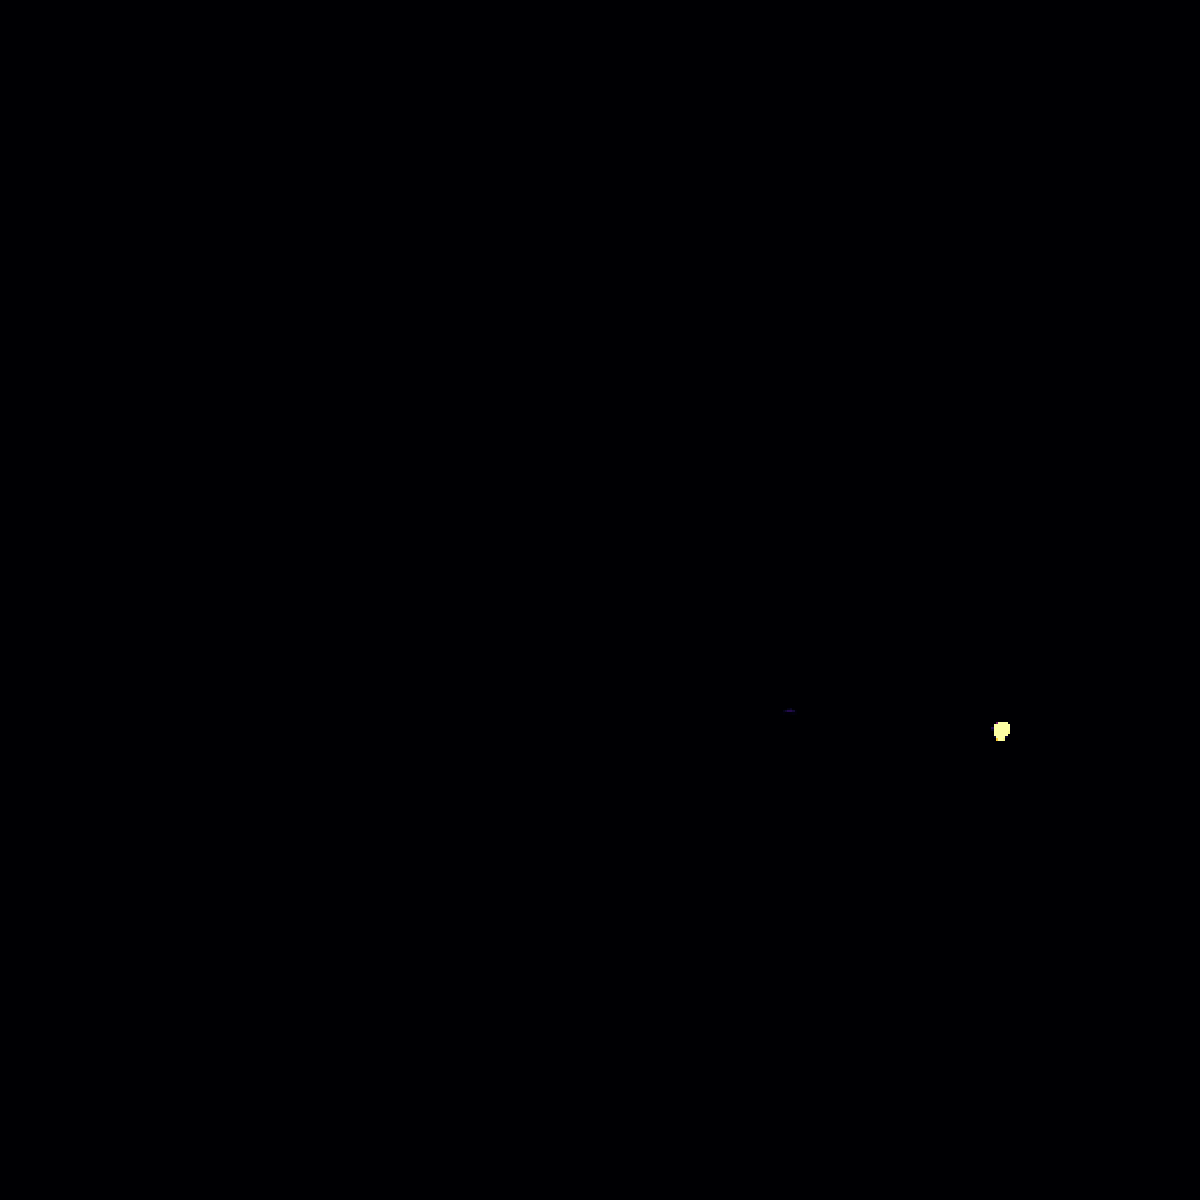

In [18]:
# ==================== GANTI PATH DI SINI ====================
# NPY_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_windowed/LIDC-IDRI-0104_16722_08531_cluster_0_slice_36.npy"
# NPY_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_windowed/LIDC-IDRI-0259_90069_11586_cluster_0_slice_32.npy"
# NPY_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/LIDC-IDRI-0037_43829_12179_cluster_0_slice_82.npy"

# NPY_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/LIDC-IDRI-0104_16722_08531_cluster_0_slice_36.npy"
# NPY_PATH = r"experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/segmentation/unet/inference/mask/test/LIDC-IDRI-0104_16722_08531_cluster_0_slice_36.npy"
# NPY_PATH = r"experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/segmentation/unet/inference/probability_npy/LIDC-IDRI-0104_16722_08531_cluster_0_slice_36.npy"

# NPY_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/mask/LIDC-IDRI-0447_56357_08059_cluster_1_slice_69.npy"
# NPY_PATH = r"experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/segmentation/unet/inference/mask/test/LIDC-IDRI-0447_56357_08059_cluster_1_slice_69.npy"
# NPY_PATH = r"experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/segmentation/unet/inference/probability_npy/LIDC-IDRI-0447_56357_08059_cluster_1_slice_69.npy"

# NPY_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/mask/LIDC-IDRI-0082_79176_44822_cluster_0_slice_175.npy"
# NPY_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_windowed/LIDC-IDRI-0987_11006_25409_cluster_2_slice_287.npy"
NPY_PATH = r"experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/segmentation/unet/inference/probability_npy/LIDC-IDRI-0987_11006_25409_cluster_2_slice_287.npy"

# Contoh Grad-CAM:
# NPY_PATH = r"experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/classification/cv_resnet50/test/gradcam_npy/layer1/LIDC-IDRI-0004_91780_58228_cluster_0_slice_74.npy"
# ============================================================

# Pengaturan yang biasanya tidak perlu diubah.
PROJECT_ROOT = None   # Isi path absolut root proyek hanya bila kernel berada di luar repo
DPI = 300
MAX_WIDTH_INCHES = 4  # Lebar output: 4 inci × 300 DPI = 1200 piksel
CMAP = "inferno"       # Grad-CAM dapat memakai inferno, viridis, atau jet
VMIN = 0
VMAX = 1
INTERPOLATION = "none"
ORIGIN = "upper"
SLICE_INDEX = None   # Isi hanya bila NPY berupa volume 3D

npy_file = resolve_npy_path(NPY_PATH, PROJECT_ROOT)
image, original_shape = load_npy_for_display(npy_file, SLICE_INDEX)
height, width = image.shape[:2]
figsize = (MAX_WIDTH_INCHES, MAX_WIDTH_INCHES * height / width)

finite_values = np.asarray(image)[np.isfinite(np.asarray(image))]
print(f"File       : {npy_file}")
print(f"Shape NPY  : {original_shape}")
print(f"Shape image: {image.shape}")
print(f"Dtype      : {image.dtype}")
print(f"Rentang    : {finite_values.min():.6g} sampai {finite_values.max():.6g}")
print(f"Output     : {round(figsize[0] * DPI)} × {round(figsize[1] * DPI)} piksel @ {DPI} DPI")

# Figure mengikuti rasio citra dan axes memenuhi seluruh kanvas.
mpl.rcParams["savefig.dpi"] = DPI
mpl.rcParams["savefig.format"] = "png"
mpl.rcParams["savefig.bbox"] = "tight"
mpl.rcParams["savefig.pad_inches"] = 0
mpl.rcParams["savefig.facecolor"] = "none"
mpl.rcParams["savefig.edgecolor"] = "none"

plt.close("all")
fig = plt.figure(figsize=figsize, dpi=DPI, frameon=False)
fig.patch.set_alpha(0)
ax = fig.add_axes([0, 0, 1, 1], frameon=False)
ax.patch.set_alpha(0)
imshow_kwargs = {
    "interpolation": INTERPOLATION,
    "origin": ORIGIN,
}
if image.ndim == 2:
    imshow_kwargs.update(cmap=CMAP, vmin=VMIN, vmax=VMAX)

ax.imshow(image, aspect="equal", **imshow_kwargs)
ax.axis("off")
ax.set_position([0, 0, 1, 1])
plt.show()

## Membuat binary mask dari lung parenchyma

Jika binary lung mask asli tidak tersedia, pendekatan paling sederhana adalah mengubah `ct_parenchyma` menjadi mask bernilai 0 dan 1: piksel di atas threshold menjadi **1**, sedangkan piksel lainnya menjadi **0**. Hasil tersedia pada variabel `lung_parenchyma_binary_mask`.

> Ini adalah proxy, bukan pengganti sempurna binary mask asli. Piksel paru yang memang bernilai nol setelah normalisasi akan ikut dianggap sebagai background.

File       : /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/LIDC-IDRI-0037_43829_12179_cluster_0_slice_82.npy
Shape      : (512, 512)
Dtype      : uint8
Nilai unik : [0, 1]
Piksel 0   : 184,444 (70.36%)
Piksel 1   : 77,700 (29.64%)


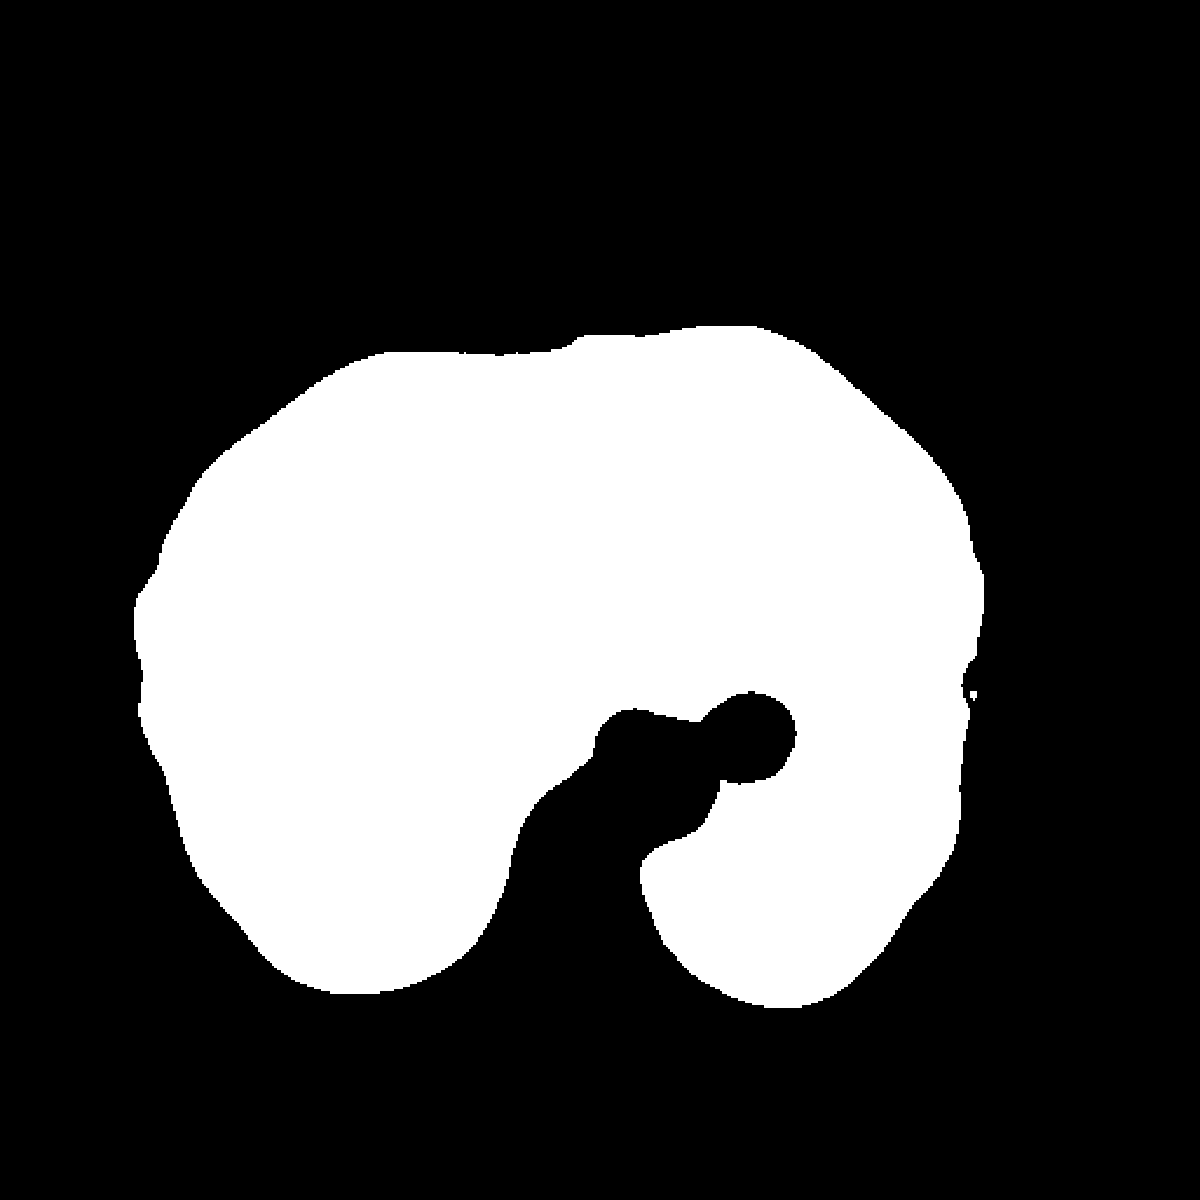

In [4]:
# ==================== GANTI PATH DI SINI ====================
# PARENCHYMA_FOR_MASK_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/LIDC-IDRI-0104_16722_08531_cluster_0_slice_36.npy"
# PARENCHYMA_FOR_MASK_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/LIDC-IDRI-0259_90069_11586_cluster_0_slice_32.npy"
PARENCHYMA_FOR_MASK_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/LIDC-IDRI-0037_43829_12179_cluster_0_slice_82.npy"
# ============================================================

BINARY_THRESHOLD = 0.0  # Nilai > threshold menjadi 1; lainnya menjadi 0
PROJECT_ROOT = None
DPI = 300
MAX_WIDTH_INCHES = 4

parenchyma_mask_file = resolve_npy_path(PARENCHYMA_FOR_MASK_PATH, PROJECT_ROOT)
parenchyma_for_mask, _ = load_npy_for_display(parenchyma_mask_file)
if parenchyma_for_mask.ndim != 2:
    raise ValueError(
        f"Citra lung parenchyma harus 2D, didapat {parenchyma_for_mask.shape}."
    )

parenchyma_values = np.ma.filled(parenchyma_for_mask, np.nan)
lung_parenchyma_binary_mask = (
    np.isfinite(parenchyma_values) & (parenchyma_values > BINARY_THRESHOLD)
).astype(np.uint8)

zero_pixels = int((lung_parenchyma_binary_mask == 0).sum())
one_pixels = int((lung_parenchyma_binary_mask == 1).sum())
total_pixels = int(lung_parenchyma_binary_mask.size)

print(f"File       : {parenchyma_mask_file}")
print(f"Shape      : {lung_parenchyma_binary_mask.shape}")
print(f"Dtype      : {lung_parenchyma_binary_mask.dtype}")
print(f"Nilai unik : {np.unique(lung_parenchyma_binary_mask).tolist()}")
print(f"Piksel 0   : {zero_pixels:,} ({100.0 * zero_pixels / total_pixels:.2f}%)")
print(f"Piksel 1   : {one_pixels:,} ({100.0 * one_pixels / total_pixels:.2f}%)")

height, width = lung_parenchyma_binary_mask.shape
figsize = (MAX_WIDTH_INCHES, MAX_WIDTH_INCHES * height / width)

mpl.rcParams["savefig.dpi"] = DPI
mpl.rcParams["savefig.format"] = "png"
mpl.rcParams["savefig.bbox"] = "tight"
mpl.rcParams["savefig.pad_inches"] = 0
mpl.rcParams["savefig.facecolor"] = "none"
mpl.rcParams["savefig.edgecolor"] = "none"

plt.close("all")
fig = plt.figure(figsize=figsize, dpi=DPI, frameon=False)
fig.patch.set_alpha(0)
ax = fig.add_axes([0, 0, 1, 1], frameon=False)
ax.patch.set_alpha(0)
ax.imshow(
    lung_parenchyma_binary_mask, cmap="gray", vmin=0, vmax=1,
    interpolation="none", origin="upper", aspect="equal"
)
ax.axis("off")
ax.set_position([0, 0, 1, 1])
plt.show()

## Overlay ground truth nodul dan inclusion pada parenkim

Sel berikut menampilkan ground truth nodul di atas citra `ct_parenchyma`. Warna dapat diisi dengan nama warna Matplotlib atau kode hex, sedangkan transparansi diatur dari 0 sampai 1.

Inclusion dihitung sebagai `100 × piksel ground truth di dalam parenkim / seluruh piksel ground truth`. Jika `LUNG_MASK_PATH` diisi, hasil dihitung secara eksak dari binary lung mask. Jika dibiarkan `None`, notebook memakai proxy konservatif `ct_parenchyma > PARENCHYMA_THRESHOLD`; nilai nol di dalam paru dapat menyebabkan hasil sedikit lebih rendah daripada inclusion sebenarnya.

In [5]:
# ======================== GANTI PATH DI SINI ========================
# PARENCHYMA_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/LIDC-IDRI-0104_16722_08531_cluster_0_slice_36.npy"
# GROUND_TRUTH_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/mask/LIDC-IDRI-0104_16722_08531_cluster_0_slice_36.npy"

# PARENCHYMA_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/LIDC-IDRI-0259_90069_11586_cluster_0_slice_32.npy"
# GROUND_TRUTH_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/mask/LIDC-IDRI-0259_90069_11586_cluster_0_slice_30.npy"

# PARENCHYMA_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/LIDC-IDRI-0037_43829_12179_cluster_0_slice_82.npy"
# GROUND_TRUTH_PATH = r"000_dataset_v2/_lidc/007_segmentation_dataset_npy/mask/LIDC-IDRI-0037_43829_12179_cluster_0_slice_82.npy"

# Opsional: isi binary lung mask asli untuk inclusion yang eksak.
LUNG_MASK_PATH = None
# ====================================================================

# Tampilan overlay — warna menerima nama (red, lime, cyan) atau hex.
OVERLAY_COLOR = "#0000ff"
OVERLAY_ALPHA = 0.45       # 0 = transparan, 1 = solid
BASE_CMAP = "gray"
BASE_VMIN = None
BASE_VMAX = None

# Threshold mask dan keluaran.
GROUND_TRUTH_THRESHOLD = 0.0
LUNG_MASK_THRESHOLD = 0.5
PARENCHYMA_THRESHOLD = 0.0
PROJECT_ROOT = None
DPI = 300
MAX_WIDTH_INCHES = 4

if not 0.0 <= OVERLAY_ALPHA <= 1.0:
    raise ValueError("OVERLAY_ALPHA harus berada pada rentang 0 sampai 1.")

parenchyma_file = resolve_npy_path(PARENCHYMA_PATH, PROJECT_ROOT)
ground_truth_file = resolve_npy_path(GROUND_TRUTH_PATH, PROJECT_ROOT)
parenchyma, _ = load_npy_for_display(parenchyma_file)

if parenchyma.ndim != 2:
    raise ValueError(f"Citra parenkim harus 2D, didapat {parenchyma.shape}.")

ground_truth_raw = np.squeeze(np.load(ground_truth_file, allow_pickle=False))
if ground_truth_raw.ndim != 2:
    raise ValueError(f"Ground truth harus 2D, didapat {ground_truth_raw.shape}.")
if not np.isfinite(ground_truth_raw).all():
    raise ValueError("Ground truth mengandung NaN atau Inf.")
ground_truth_mask = ground_truth_raw > GROUND_TRUTH_THRESHOLD

if parenchyma.shape != ground_truth_mask.shape:
    raise ValueError(
        f"Shape tidak sama: parenkim={parenchyma.shape}, "
        f"ground truth={ground_truth_mask.shape}."
    )

if LUNG_MASK_PATH is not None:
    lung_mask_file = resolve_npy_path(LUNG_MASK_PATH, PROJECT_ROOT)
    lung_mask_raw = np.squeeze(np.load(lung_mask_file, allow_pickle=False))
    if lung_mask_raw.ndim != 2 or lung_mask_raw.shape != ground_truth_mask.shape:
        raise ValueError(
            f"Binary lung mask harus 2D dan berbentuk {ground_truth_mask.shape}; "
            f"didapat {lung_mask_raw.shape}."
        )
    if not np.isfinite(lung_mask_raw).all():
        raise ValueError("Binary lung mask mengandung NaN atau Inf.")
    lung_mask = lung_mask_raw > LUNG_MASK_THRESHOLD
    inclusion_method = "eksak dari binary lung mask"
else:
    parenchyma_values = np.ma.filled(parenchyma, np.nan)
    lung_mask = np.isfinite(parenchyma_values) & (parenchyma_values > PARENCHYMA_THRESHOLD)
    inclusion_method = "proxy konservatif: ct_parenchyma > threshold"

ground_truth_pixels = int(ground_truth_mask.sum())
if ground_truth_pixels == 0:
    raise ValueError("Ground truth tidak memiliki piksel positif pada threshold saat ini.")
inside_mask = ground_truth_mask & lung_mask
inside_pixels = int(inside_mask.sum())
outside_pixels = ground_truth_pixels - inside_pixels
inclusion_percent = 100.0 * inside_pixels / ground_truth_pixels

print(f"Parenkim           : {parenchyma_file}")
print(f"Ground truth       : {ground_truth_file}")
print(f"Metode inclusion   : {inclusion_method}")
print(f"Piksel ground truth: {ground_truth_pixels:,}")
print(f"Piksel di dalam    : {inside_pixels:,}")
print(f"Piksel di luar     : {outside_pixels:,}")
print(f"Inclusion          : {inclusion_percent:.2f}%")

height, width = parenchyma.shape
figsize = (MAX_WIDTH_INCHES, MAX_WIDTH_INCHES * height / width)
overlay_rgba = np.zeros((height, width, 4), dtype=np.float32)
overlay_rgba[ground_truth_mask, :3] = mpl.colors.to_rgb(OVERLAY_COLOR)
overlay_rgba[ground_truth_mask, 3] = OVERLAY_ALPHA

mpl.rcParams["savefig.dpi"] = DPI
mpl.rcParams["savefig.format"] = "png"
mpl.rcParams["savefig.bbox"] = "tight"
mpl.rcParams["savefig.pad_inches"] = 0
mpl.rcParams["savefig.facecolor"] = "none"
mpl.rcParams["savefig.edgecolor"] = "none"

plt.close("all")
fig = plt.figure(figsize=figsize, dpi=DPI, frameon=False)
fig.patch.set_alpha(0)
ax = fig.add_axes([0, 0, 1, 1], frameon=False)
ax.patch.set_alpha(0)
ax.imshow(
    parenchyma, cmap=BASE_CMAP, vmin=BASE_VMIN, vmax=BASE_VMAX,
    interpolation="none", origin="upper", aspect="equal"
)
ax.imshow(overlay_rgba, interpolation="none", origin="upper", aspect="equal")
ax.axis("off")
ax.set_position([0, 0, 1, 1])
plt.show()

NameError: name 'PARENCHYMA_PATH' is not defined

## LRP dan Grad-CAM dengan cincin ground truth nodul

Section ini menampilkan XAI untuk **LIDC-IDRI-0082 cluster 0 slice 175** dan **LIDC-IDRI-0987 cluster 2 slice 287**. Model yang tersedia adalah ResNet50 dan multistage direct-guided ResNet50; Grad-CAM dan LRP ditampilkan untuk setiap model.

Setiap XAI dibuat sebagai **figure terpisah**, sehingga tombol Save/Copy bekerja untuk satu gambar saja. Seperti visualisasi eksperimen asli, XAI ditumpuk transparan di atas CT parenkim dengan alpha konstan. Ground truth ditandai cincin berlubang tanpa fill: outline luar hitam serta badan cincin kuning, sehingga warna heatmap di dalam nodul tidak tertutup oleh mask ground truth. `layer4` digunakan sebagai default dan dapat diganti pada konfigurasi.

LIDC-IDRI-0082 | cluster 0 | slice 175 | Direct-guided ResNet50 | Grad-CAM
File: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/classification/multistage_direct_guided_cv_resnet50/test/gradcam_npy/layer4/LIDC-IDRI-0082_79176_44822_cluster_0_slice_175.npy


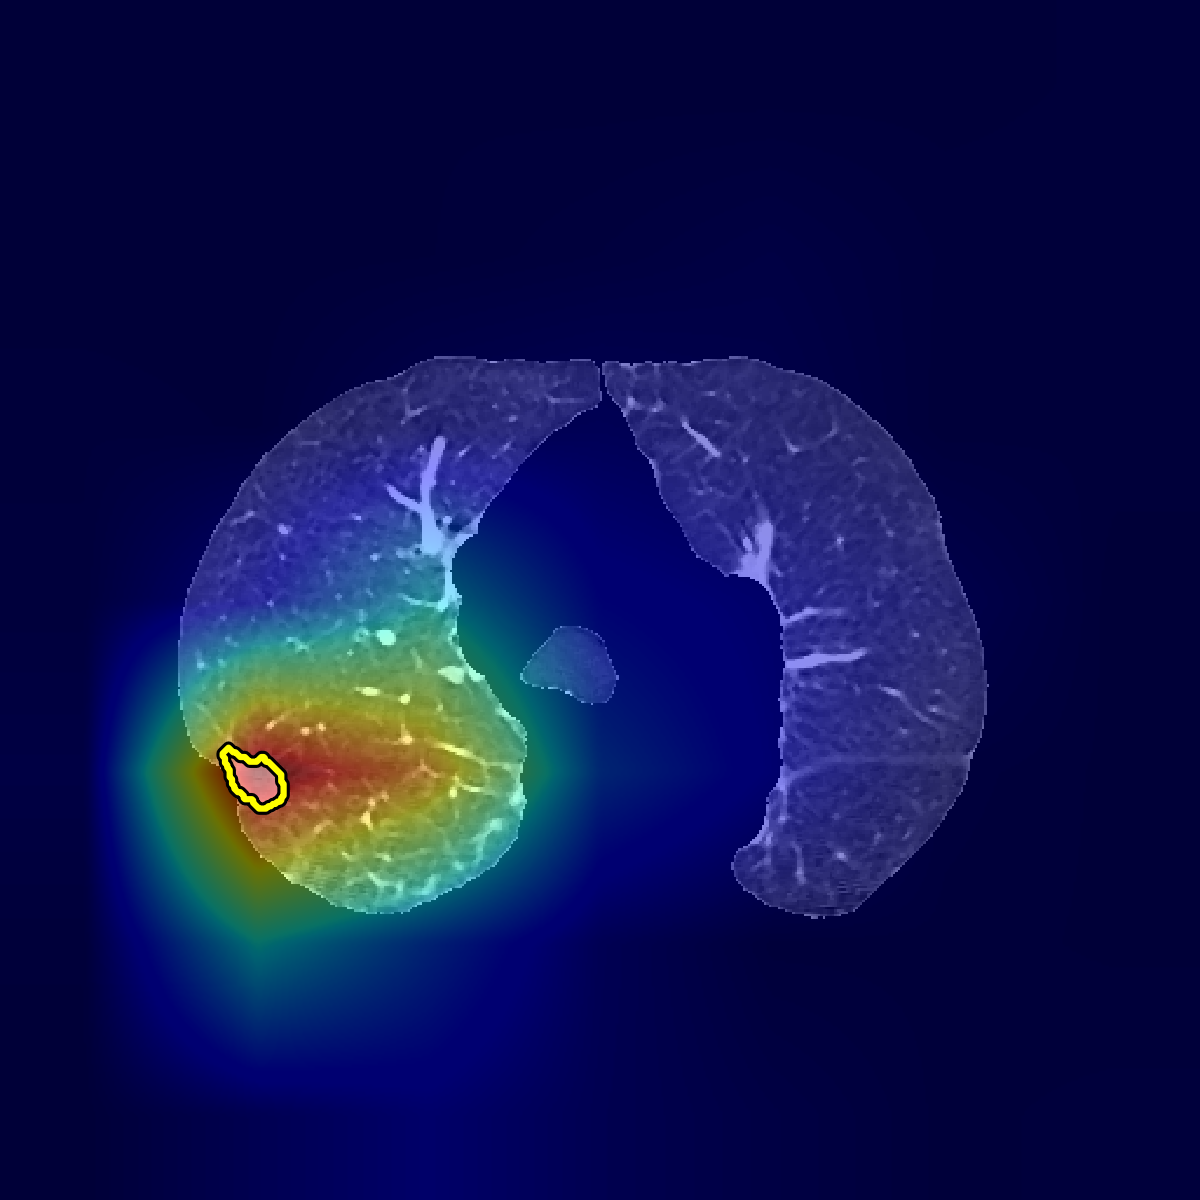

LIDC-IDRI-0082 | cluster 0 | slice 175 | Direct-guided ResNet50 | LRP
File: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/classification/multistage_direct_guided_cv_resnet50/test/lrp_npy/layer4/LIDC-IDRI-0082_79176_44822_cluster_0_slice_175.npy


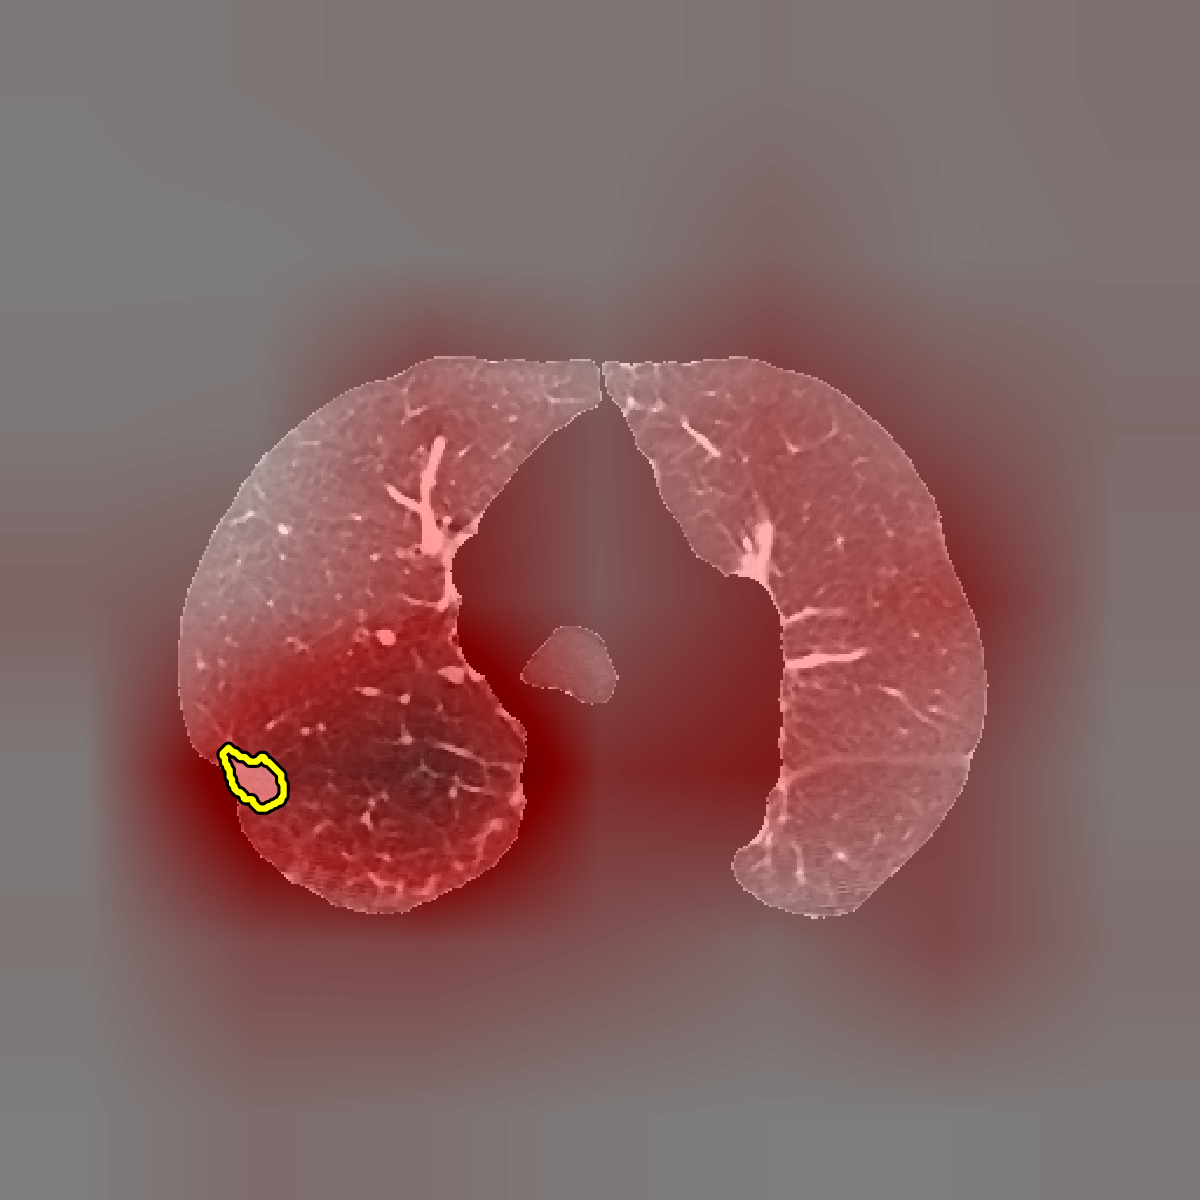

LIDC-IDRI-0082 | cluster 0 | slice 175 | ResNet50 | Grad-CAM
File: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/classification/cv_resnet50/test/gradcam_npy/layer4/LIDC-IDRI-0082_79176_44822_cluster_0_slice_175.npy


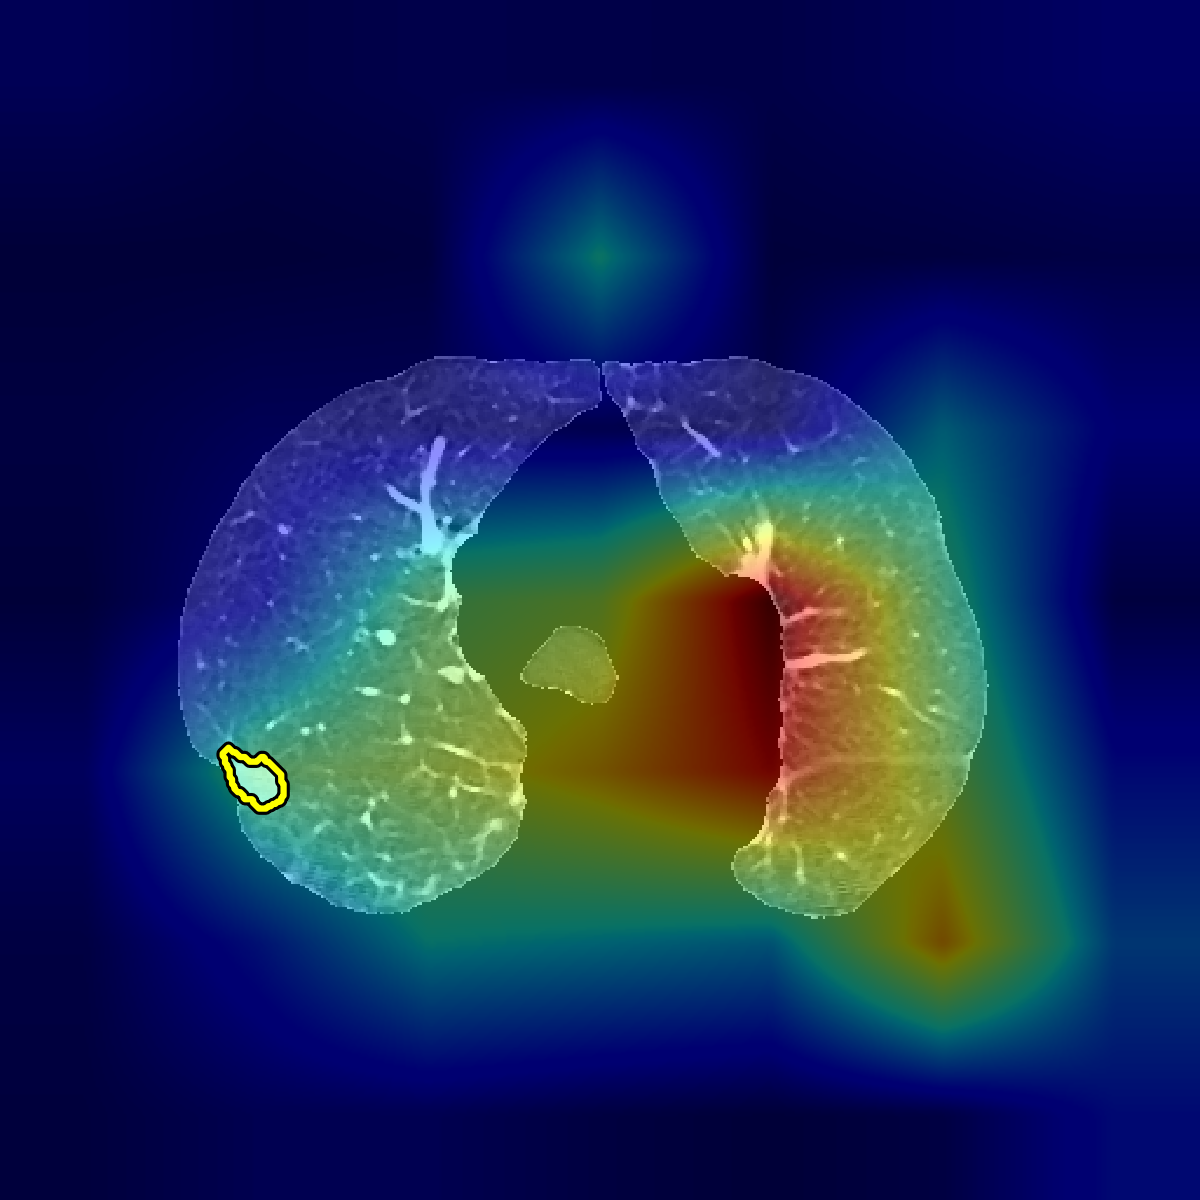

LIDC-IDRI-0082 | cluster 0 | slice 175 | ResNet50 | LRP
File: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/classification/cv_resnet50/test/lrp_npy/layer4/LIDC-IDRI-0082_79176_44822_cluster_0_slice_175.npy


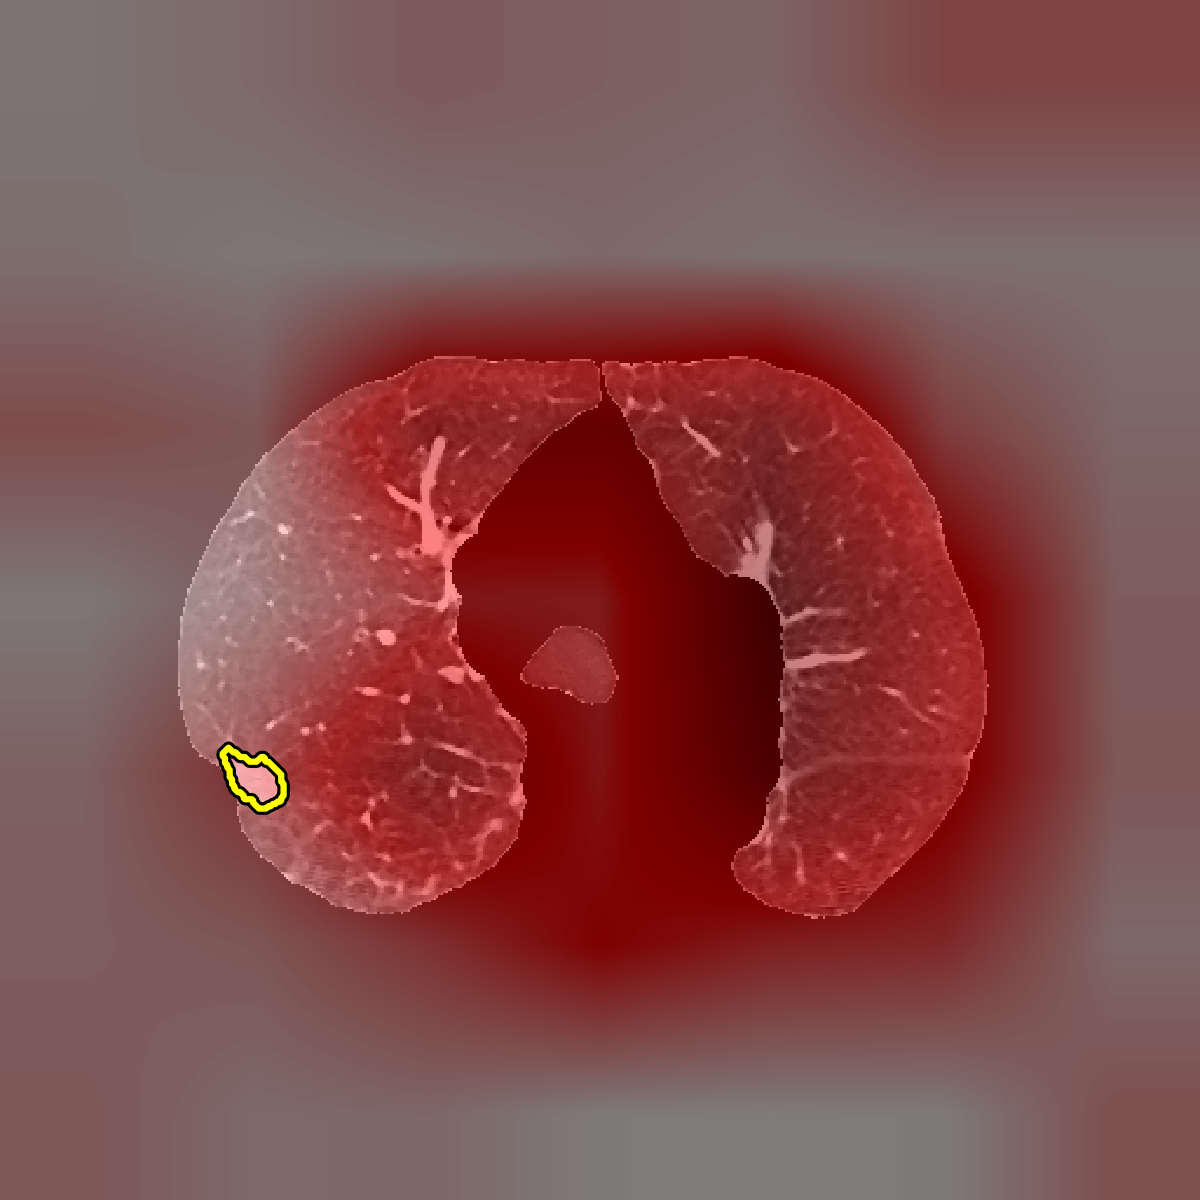

LIDC-IDRI-0987 | cluster 2 | slice 287 | Direct-guided ResNet50 | Grad-CAM
File: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/classification/multistage_direct_guided_cv_resnet50/test/gradcam_npy/layer4/LIDC-IDRI-0987_11006_25409_cluster_2_slice_287.npy


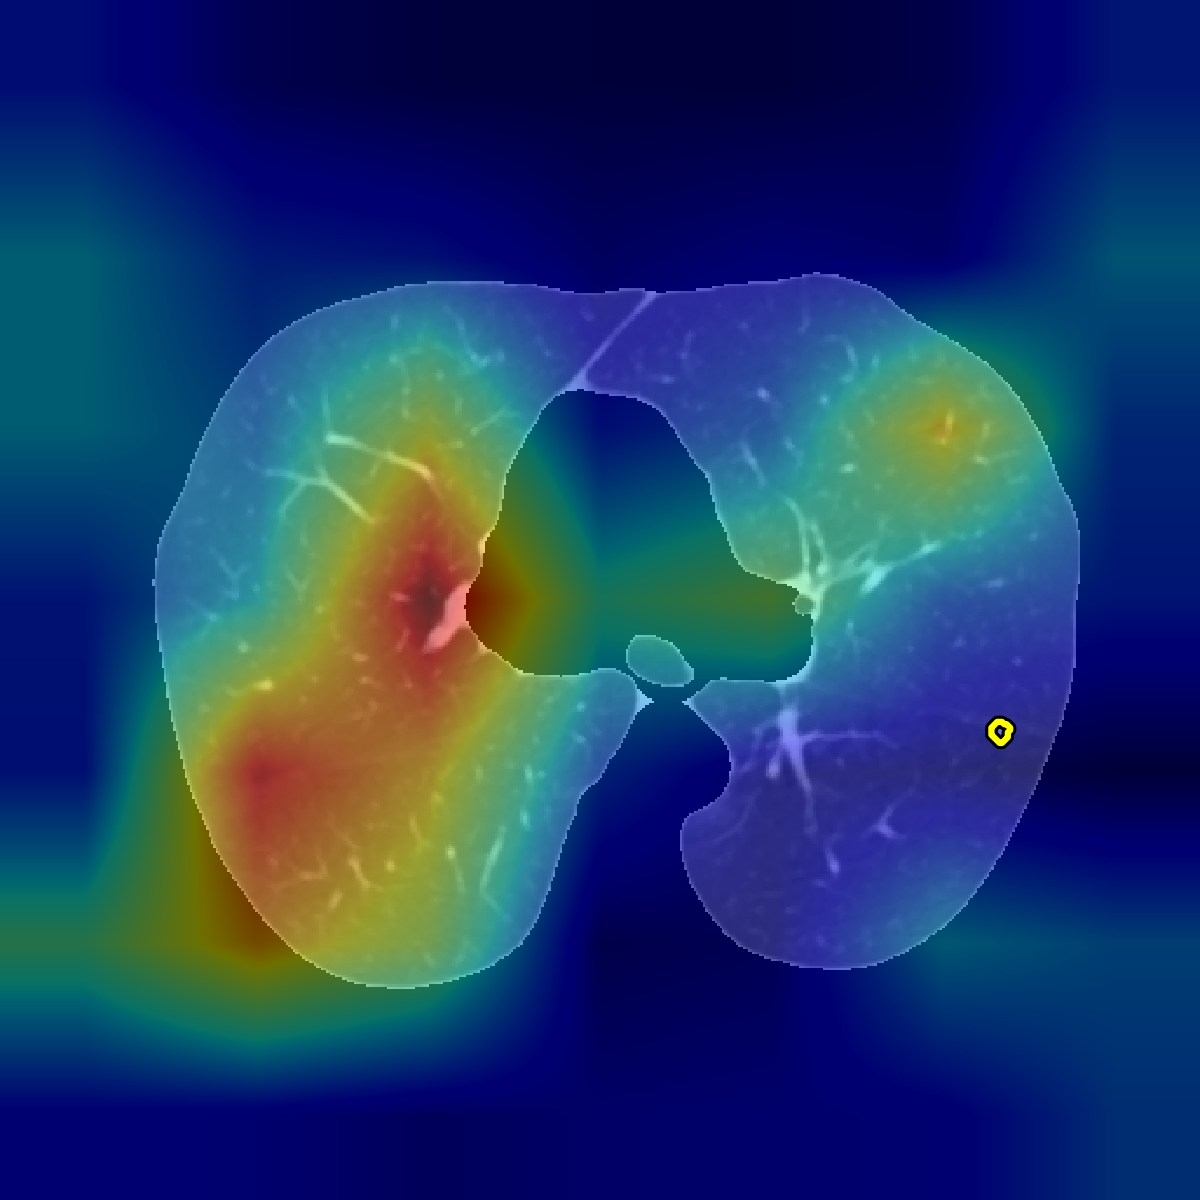

LIDC-IDRI-0987 | cluster 2 | slice 287 | Direct-guided ResNet50 | LRP
File: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/classification/multistage_direct_guided_cv_resnet50/test/lrp_npy/layer4/LIDC-IDRI-0987_11006_25409_cluster_2_slice_287.npy


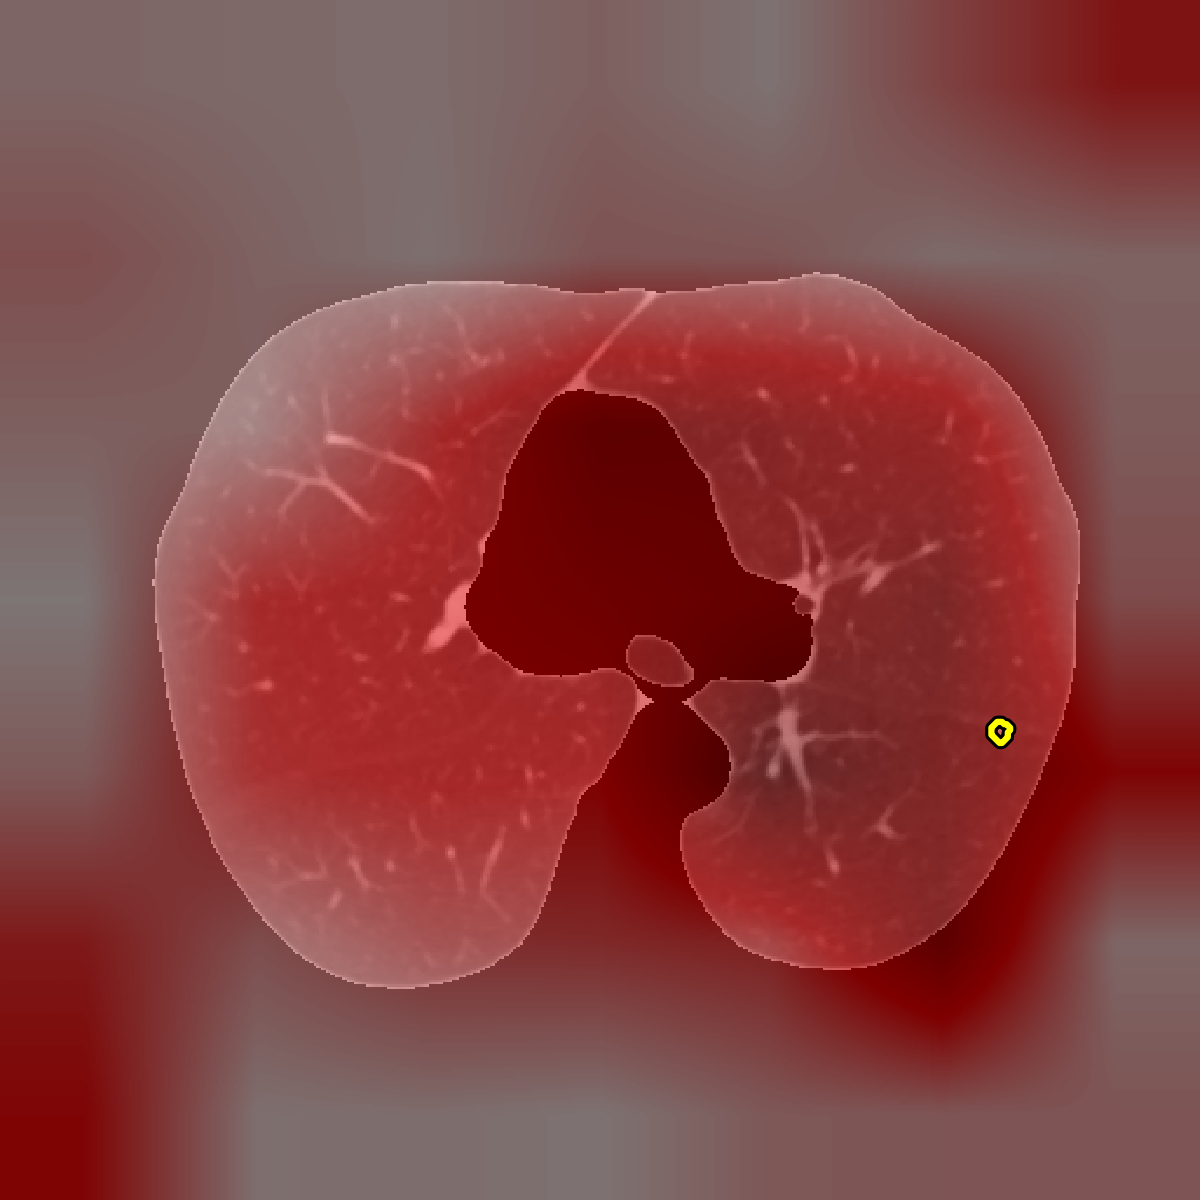

LIDC-IDRI-0987 | cluster 2 | slice 287 | ResNet50 | Grad-CAM
File: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/classification/cv_resnet50/test/gradcam_npy/layer4/LIDC-IDRI-0987_11006_25409_cluster_2_slice_287.npy


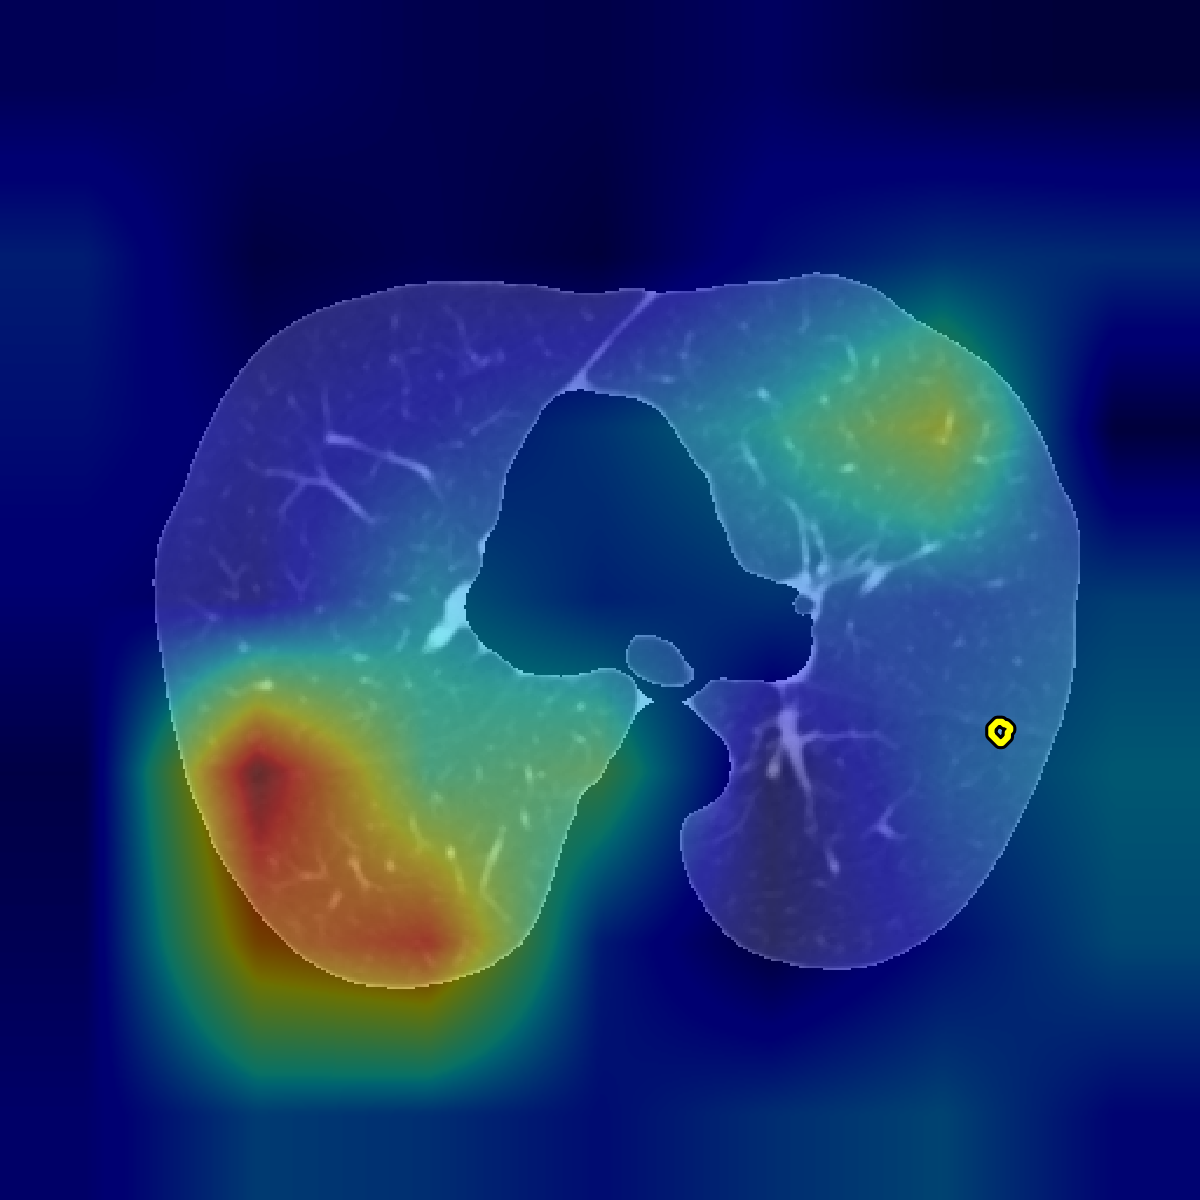

LIDC-IDRI-0987 | cluster 2 | slice 287 | ResNet50 | LRP
File: /run/media/dityanugroho/New Volume/mask-guided-lung-nodule-xai/experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/classification/cv_resnet50/test/lrp_npy/layer4/LIDC-IDRI-0987_11006_25409_cluster_2_slice_287.npy


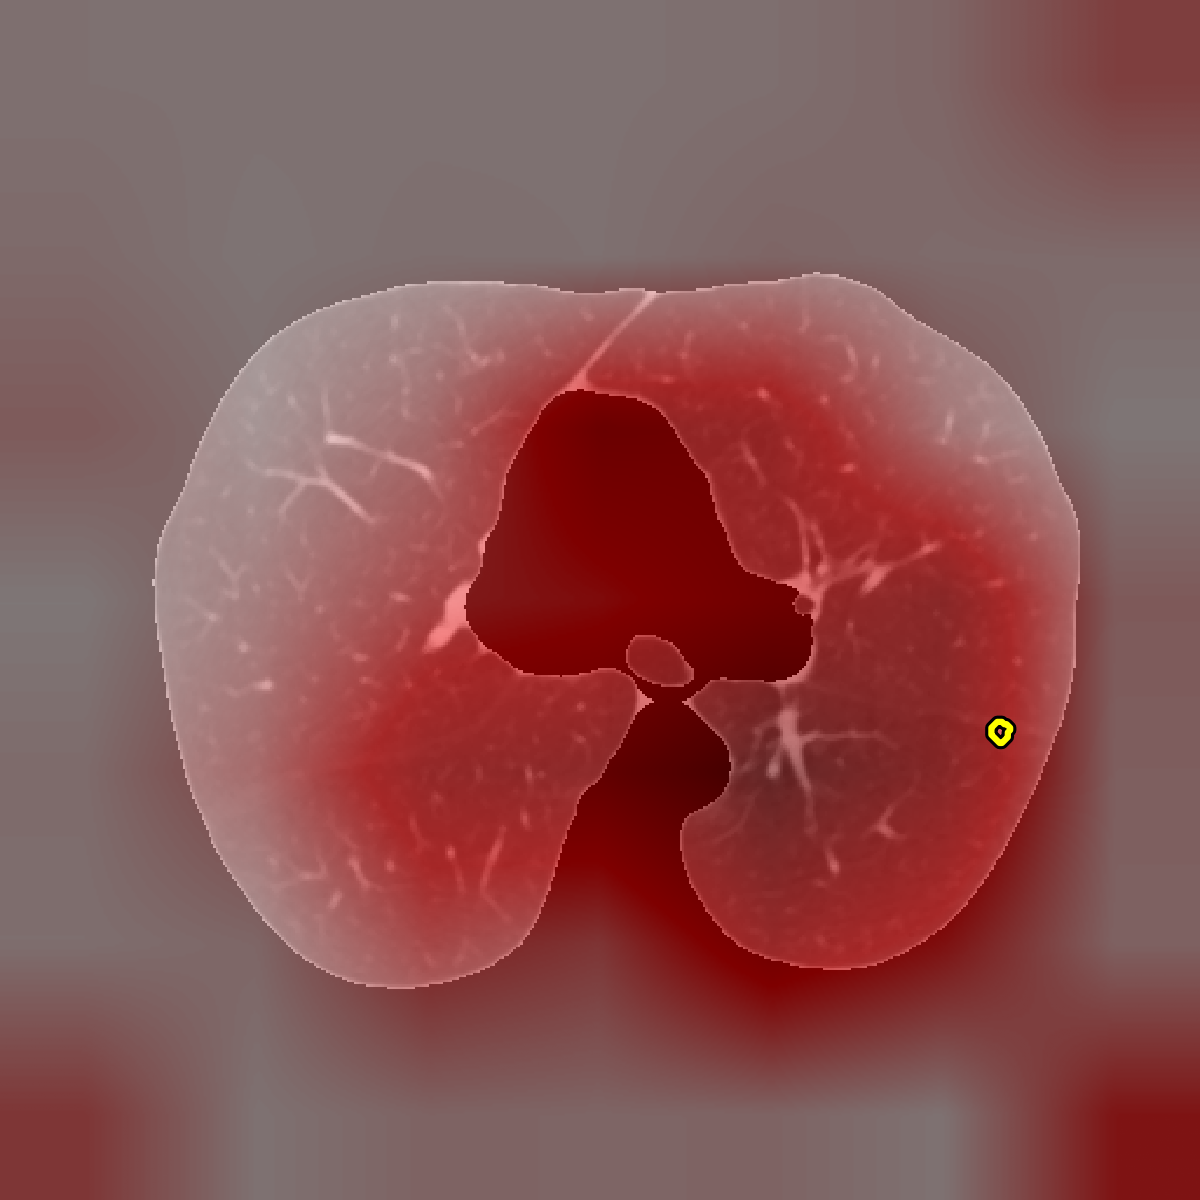

In [10]:
# Pilih satu atau kedua model.
MODELS_TO_SHOW = ["direct_guided", "resnet50"]
XAI_LAYER = "layer4"  # layer1, layer2, layer3, atau layer4

# Sama dengan gaya visualisasi eksperimen asli.
GRADCAM_CMAP = "jet"
GRADCAM_ALPHA = 0.45
GRADCAM_VMIN, GRADCAM_VMAX = 0.0, 1.0
LRP_CMAP = "seismic"
LRP_ALPHA = 0.50
LRP_VMIN, LRP_VMAX = -1.0, 1.0
RING_COLOR = "#FFFF00"       # Badan cincin: kuning
RING_OUTER_COLOR = "#000000" # Outline luar: hitam
RING_BODY_WIDTH = 1.5
RING_OUTER_WIDTH = 3.0
DPI = 300
FIGSIZE_INCHES = (4, 4)
PROJECT_ROOT = None

EXPERIMENT_ROOT = (
    "experiment_results/fa028196-fd4c-441f-a5d3-3efb9707e7f9/"
    "classification"
)
MODEL_DIRECTORIES = {
    "direct_guided": "multistage_direct_guided_cv_resnet50",
    "resnet50": "cv_resnet50",
}
MODEL_LABELS = {
    "direct_guided": "Direct-guided ResNet50",
    "resnet50": "ResNet50",
}
XAI_METHODS = {
    "Grad-CAM": "gradcam_npy",
    "LRP": "lrp_npy",
}
CASES = [
    {
        "label": "LIDC-IDRI-0082 | cluster 0 | slice 175",
        "filename": "LIDC-IDRI-0082_79176_44822_cluster_0_slice_175.npy",
        "ground_truth": (
            "000_dataset_v2/_lidc/007_segmentation_dataset_npy/mask/"
            "LIDC-IDRI-0082_79176_44822_cluster_0_slice_175.npy"
        ),
        "parenchyma": (
            "000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/"
            "LIDC-IDRI-0082_79176_44822_cluster_0_slice_175.npy"
        ),
    },
    {
        "label": "LIDC-IDRI-0987 | cluster 2 | slice 287",
        "filename": "LIDC-IDRI-0987_11006_25409_cluster_2_slice_287.npy",
        "ground_truth": (
            "000_dataset_v2/_lidc/007_segmentation_dataset_npy/mask/"
            "LIDC-IDRI-0987_11006_25409_cluster_2_slice_287.npy"
        ),
        "parenchyma": (
            "000_dataset_v2/_lidc/007_segmentation_dataset_npy/ct_parenchyma/"
            "LIDC-IDRI-0987_11006_25409_cluster_2_slice_287.npy"
        ),
    },
]

invalid_models = set(MODELS_TO_SHOW) - set(MODEL_DIRECTORIES)
if invalid_models:
    raise ValueError(f"Model tidak dikenal: {sorted(invalid_models)}")
if XAI_LAYER not in {"layer1", "layer2", "layer3", "layer4"}:
    raise ValueError("XAI_LAYER harus layer1, layer2, layer3, atau layer4.")
if RING_OUTER_WIDTH <= RING_BODY_WIDTH:
    raise ValueError("RING_OUTER_WIDTH harus lebih besar dari RING_BODY_WIDTH.")


def resize_map_bilinear(values, target_shape):
    """Resize map 2D secara bilinear hanya dengan NumPy."""
    values = np.asarray(values, dtype=np.float32)
    target_height, target_width = target_shape
    source_height, source_width = values.shape
    if values.shape == target_shape:
        return values
    source_x = np.arange(source_width, dtype=np.float32)
    target_x = (
        (np.arange(target_width) + 0.5) * source_width / target_width - 0.5
    ).clip(0, source_width - 1)
    horizontal = np.empty((source_height, target_width), dtype=np.float32)
    for row_index in range(source_height):
        horizontal[row_index] = np.interp(
            target_x, source_x, values[row_index]
        )
    source_y = np.arange(source_height, dtype=np.float32)
    target_y = (
        (np.arange(target_height) + 0.5) * source_height / target_height - 0.5
    ).clip(0, source_height - 1)
    resized = np.empty((target_height, target_width), dtype=np.float32)
    for column_index in range(target_width):
        resized[:, column_index] = np.interp(
            target_y, source_y, horizontal[:, column_index]
        )
    return resized


def add_ground_truth_ring(axis, mask):
    """Tambahkan cincin berlubang hitam-kuning pada batas mask asli."""
    binary_mask = np.asarray(mask, dtype=bool)
    if not binary_mask.any():
        raise ValueError("Ground truth tidak memiliki piksel positif.")
    mask_values = binary_mask.astype(np.float32)
    axis.contour(
        mask_values, levels=[0.5], colors=[RING_OUTER_COLOR],
        linewidths=RING_OUTER_WIDTH,
    )
    axis.contour(
        mask_values, levels=[0.5], colors=[RING_COLOR],
        linewidths=RING_BODY_WIDTH,
    )


mpl.rcParams["savefig.dpi"] = DPI
mpl.rcParams["savefig.format"] = "png"
mpl.rcParams["savefig.bbox"] = "tight"
mpl.rcParams["savefig.pad_inches"] = 0
mpl.rcParams["savefig.facecolor"] = "none"
mpl.rcParams["savefig.edgecolor"] = "none"

# Setiap iterasi menghasilkan figure mandiri, bukan subplot gabungan.
for case in CASES:
    ground_truth_file = resolve_npy_path(case["ground_truth"], PROJECT_ROOT)
    parenchyma_file = resolve_npy_path(case["parenchyma"], PROJECT_ROOT)
    ground_truth_raw = np.squeeze(np.load(ground_truth_file, allow_pickle=False))
    if ground_truth_raw.ndim != 2:
        raise ValueError(
            f"Ground truth {ground_truth_file.name} harus 2D, "
            f"didapat {ground_truth_raw.shape}."
        )
    ground_truth_mask = ground_truth_raw.astype(bool)
    display_ct, _ = load_npy_for_display(parenchyma_file)
    if display_ct.ndim != 2 or display_ct.shape != ground_truth_mask.shape:
        raise ValueError(
            f"Shape CT dan ground truth harus sama: CT={display_ct.shape}, "
            f"ground truth={ground_truth_mask.shape}."
        )

    for model_key in MODELS_TO_SHOW:
        for method_label, method_directory in XAI_METHODS.items():
            xai_path = (
                f"{EXPERIMENT_ROOT}/{MODEL_DIRECTORIES[model_key]}/test/"
                f"{method_directory}/{XAI_LAYER}/{case['filename']}"
            )
            xai_file = resolve_npy_path(xai_path, PROJECT_ROOT)
            xai_image, _ = load_npy_for_display(xai_file)
            if xai_image.ndim != 2:
                raise ValueError(f"XAI harus 2D, didapat {xai_image.shape}.")

            display_xai = resize_map_bilinear(xai_image, display_ct.shape)
            if method_label == "Grad-CAM":
                xai_cmap, xai_alpha = GRADCAM_CMAP, GRADCAM_ALPHA
                xai_vmin, xai_vmax = GRADCAM_VMIN, GRADCAM_VMAX
            else:
                xai_cmap, xai_alpha = LRP_CMAP, LRP_ALPHA
                xai_vmin, xai_vmax = LRP_VMIN, LRP_VMAX

            print(f"{case['label']} | {MODEL_LABELS[model_key]} | {method_label}")
            print(f"File: {xai_file}")

            fig = plt.figure(figsize=FIGSIZE_INCHES, dpi=DPI, frameon=False)
            fig.patch.set_alpha(0)
            ax = fig.add_axes([0, 0, 1, 1], frameon=False)
            ax.patch.set_alpha(0)
            ax.imshow(
                display_ct, cmap="gray", vmin=0.0, vmax=1.0,
                interpolation="none", origin="upper", aspect="equal"
            )
            ax.imshow(
                display_xai, cmap=xai_cmap, alpha=xai_alpha,
                vmin=xai_vmin, vmax=xai_vmax, interpolation="bilinear",
                origin="upper", aspect="equal"
            )
            add_ground_truth_ring(ax, ground_truth_mask)

            ax.set_xlim(-0.5, display_ct.shape[1] - 0.5)
            ax.set_ylim(display_ct.shape[0] - 0.5, -0.5)
            ax.axis("off")
            ax.set_position([0, 0, 1, 1])
            plt.show()